# 02 — Paderborn (PU) Bearing Data: Load & Explore

Second dataset, and the one that matches our sensor list best: PU records
**vibration _and_ two motor phase currents** at 64 kHz (plus speed, torque,
radial force, temperature) on a 425 W PMSM test rig.

Starter subset (see `src/download_paderborn.py`):

| Code | Damage | Origin |
|---|---|---|
| K001 | healthy | run-in > 50 h |
| KA01 | outer race | **artificial** (EDM) |
| KI01 | inner race | **artificial** (EDM) |
| KA04 | outer race | **real** (accelerated lifetime test) |
| KI04 | inner race | **real** (accelerated lifetime test) |

Two questions for this notebook:
1. Do the same simple features (RMS, Crest Factor, Peak-to-Peak) that separated
   CWRU classes also work here — on vibration *and* on motor current?
2. Does a model's view of **artificial** damage resemble **real** damage?
   (This is the physical analogue of our RQ4 sim-to-real question: artificial
   damage : real damage :: simulated faults : deployment faults.)

We fix the operating condition to the standard one used in the PU paper:
`N15_M07_F10` = 1500 rpm, 0.7 Nm load torque, 1000 N radial force.
Each bearing has 20 repeated 4 s measurements under this condition.

In [1]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat

DATA_DIR = pathlib.Path("../data/raw/paderborn")
CONDITION = "N15_M07_F10"  # 1500 rpm, 0.7 Nm, 1000 N — PU standard condition
FS_HIGH_HZ = 64_000        # vibration + phase currents sampling rate

BEARINGS = {
    "Healthy":  "K001",
    "OR-art":   "KA01",  # outer race, artificial (EDM)
    "IR-art":   "KI01",  # inner race, artificial (EDM)
    "OR-real":  "KA04",  # outer race, real (lifetime test)
    "IR-real":  "KI04",  # inner race, real (lifetime test)
}

## File structure

Each `.mat` file holds one MATLAB struct named like the file
(e.g. `N15_M07_F10_K001_1`). Its `Y` field is an array of named channels;
we unpack it into a plain `{name: 1-D array}` dict and look at what's inside.

In [2]:
def load_channels(mat_path):
    """Load a PU .mat file -> dict of channel name -> 1-D numpy array."""
    mat_path = pathlib.Path(mat_path)
    mat = loadmat(mat_path)
    struct = mat[mat_path.stem]
    channels = struct["Y"][0, 0][0]
    return {str(ch["Name"][0]): ch["Data"].squeeze() for ch in channels}


def pu_file(code, run):
    return DATA_DIR / code / f"{CONDITION}_{code}_{run}.mat"


example = load_channels(pu_file("K001", 1))
for name, data in example.items():
    print(f"{name:20s} {len(data):>9,} samples  (~{len(data) / 4:,.0f} Hz over 4 s)")

force                   16,001 samples  (~4,000 Hz over 4 s)
phase_current_1        256,001 samples  (~64,000 Hz over 4 s)
phase_current_2        256,001 samples  (~64,000 Hz over 4 s)
speed                   16,001 samples  (~4,000 Hz over 4 s)
temp_2_bearing_module         5 samples  (~1 Hz over 4 s)
torque                  16,001 samples  (~4,000 Hz over 4 s)
vibration_1            256,001 samples  (~64,000 Hz over 4 s)


## Time-domain view: vibration

Same drill as CWRU (notebook 01): 0.1 s window of the vibration channel for
each bearing. Watch for two things: fault impulses vs. the healthy baseline,
and whether **real** damage (KA04/KI04) looks like its **artificial**
counterpart (KA01/KI01).

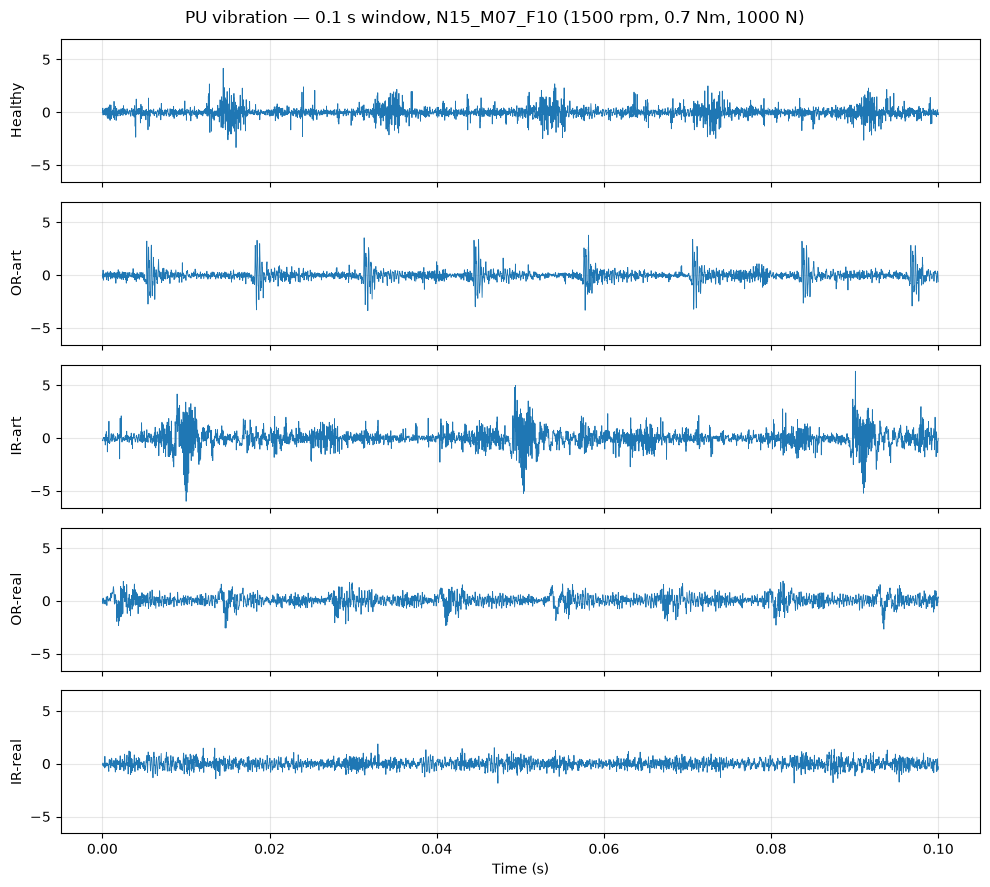

In [3]:
signals = {label: load_channels(pu_file(code, 1)) for label, code in BEARINGS.items()}

window = int(0.1 * FS_HIGH_HZ)  # 0.1 s at 64 kHz
t = np.arange(window) / FS_HIGH_HZ

fig, axes = plt.subplots(5, 1, figsize=(10, 9), sharex=True, sharey=True)
for ax, (label, chans) in zip(axes, signals.items()):
    ax.plot(t, chans["vibration_1"][:window], linewidth=0.6)
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Time (s)")
fig.suptitle(f"PU vibration — 0.1 s window, {CONDITION} (1500 rpm, 0.7 Nm, 1000 N)")
plt.tight_layout()
plt.show()

## Time-domain view: motor phase current

This is what CWRU cannot show us. The current waveform is dominated by the
drive's PWM/electrical fundamental, so bearing-fault signatures are far
subtler than in vibration — expect the traces to look nearly identical to the
eye. That subtlety is exactly why current-based diagnosis is valuable
(no extra sensor needed on a real motor) and harder.

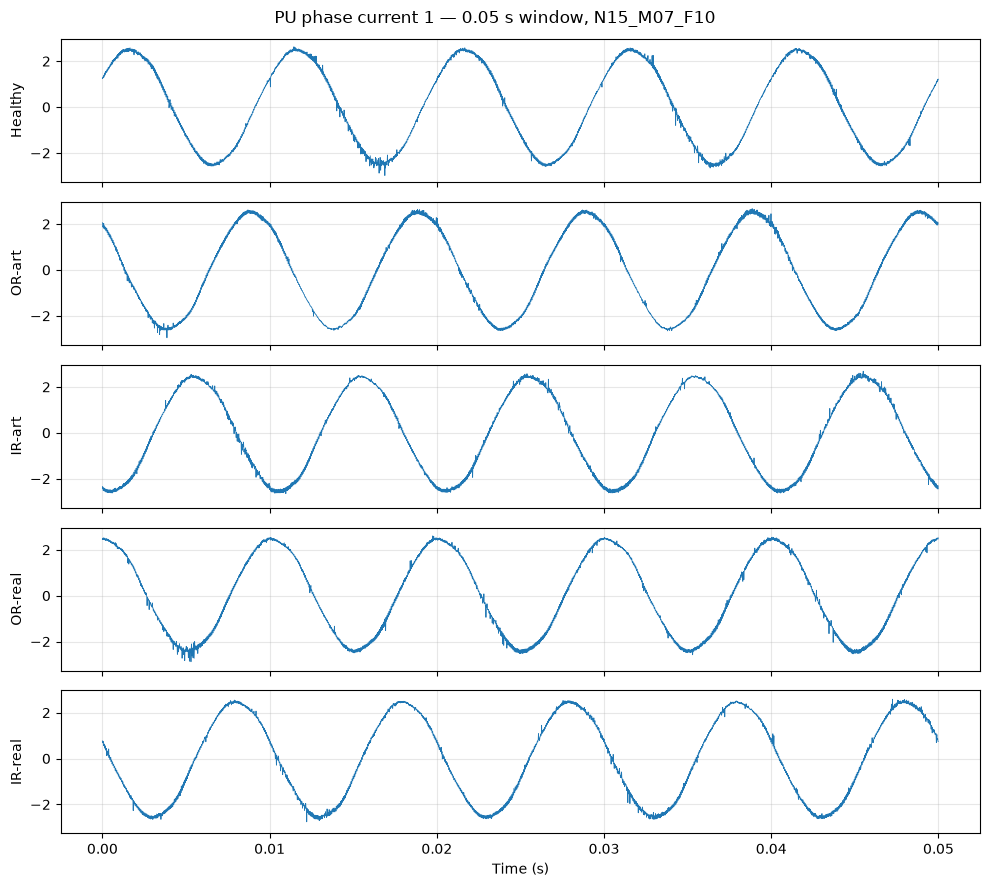

In [4]:
window_c = int(0.05 * FS_HIGH_HZ)  # 0.05 s — a few electrical periods
t_c = np.arange(window_c) / FS_HIGH_HZ

fig, axes = plt.subplots(5, 1, figsize=(10, 9), sharex=True, sharey=True)
for ax, (label, chans) in zip(axes, signals.items()):
    ax.plot(t_c, chans["phase_current_1"][:window_c], linewidth=0.6)
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Time (s)")
fig.suptitle(f"PU phase current 1 — 0.05 s window, {CONDITION}")
plt.tight_layout()
plt.show()

## Feature/target table: vibration + current

Same recipe as notebook 01 (RMS, Crest Factor, Peak-to-Peak per window),
now computed on **both** the vibration and the phase-current channel, over all
20 measurement runs per bearing. Window = 8192 samples at 64 kHz = 128 ms,
close to the 170 ms windows used on CWRU.

In [5]:
N_RUNS = 20
WINDOW_SIZE = 8192  # 128 ms at 64 kHz


def window_features(sig, window_size, prefix):
    """Non-overlapping windows -> DataFrame of RMS / CrestFactor / PeakToPeak."""
    n_windows = len(sig) // window_size
    w = sig[: n_windows * window_size].reshape(n_windows, window_size)
    rms = np.sqrt(np.mean(w**2, axis=1))
    peak = np.max(np.abs(w), axis=1)
    return pd.DataFrame({
        f"{prefix}_RMS": rms,
        f"{prefix}_CrestFactor": np.where(rms > 0, peak / rms, np.nan),
        f"{prefix}_PeakToPeak": w.max(axis=1) - w.min(axis=1),
    })


tables = []
for label, code in BEARINGS.items():
    for run in range(1, N_RUNS + 1):
        chans = load_channels(pu_file(code, run))
        feats = pd.concat(
            [
                window_features(chans["vibration_1"], WINDOW_SIZE, "Vib"),
                window_features(chans["phase_current_1"], WINDOW_SIZE, "Cur"),
            ],
            axis=1,
        )
        feats["Status"] = label
        feats["Run"] = run
        tables.append(feats)

dataset = pd.concat(tables, ignore_index=True)
print(f"Total rows: {len(dataset)}  "
      f"({len(BEARINGS)} bearings x {N_RUNS} runs, window = {WINDOW_SIZE} samples)")
dataset.sample(8, random_state=0)

Total rows: 3102  (5 bearings x 20 runs, window = 8192 samples)


,Vib_RMS,Vib_CrestFactor,Vib_PeakToPeak,Cur_RMS,Cur_CrestFactor,Cur_PeakToPeak,Status,Run
1017,0.540142,6.486103,6.661987,1.803864,1.556749,5.489590,OR-art,13
1197,0.540844,6.799309,6.829834,1.795812,1.683779,5.995845,OR-art,19
2576,0.356224,6.073973,4.266357,1.790689,1.635131,5.736174,IR-real,4
2850,0.367674,6.216832,4.202271,1.774134,1.787048,5.820894,IR-real,12
982,0.544225,6.751467,6.817627,1.778635,1.734894,5.688648,OR-art,12
3043,0.387995,7.440729,5.642700,1.779152,1.790912,5.790588,IR-real,19
1887,0.482006,6.679590,5.148315,1.731851,1.613526,5.377319,OR-real,1
2235,0.479804,6.443117,5.654907,1.722180,1.703377,5.481325,OR-real,13


## Do the features separate the classes?

Left: vibration features. Right: the same features on motor current.
Two things to check:

1. **Modality gap** — vibration should separate classes far better than
   current does with these crude time-domain features.
2. **Artificial vs. real** — do OR-art/OR-real (and IR-art/IR-real) overlap,
   or does each damage origin form its own cluster? If they don't overlap,
   that is CWRU-style evidence for Paper 4's domain-gap warning.

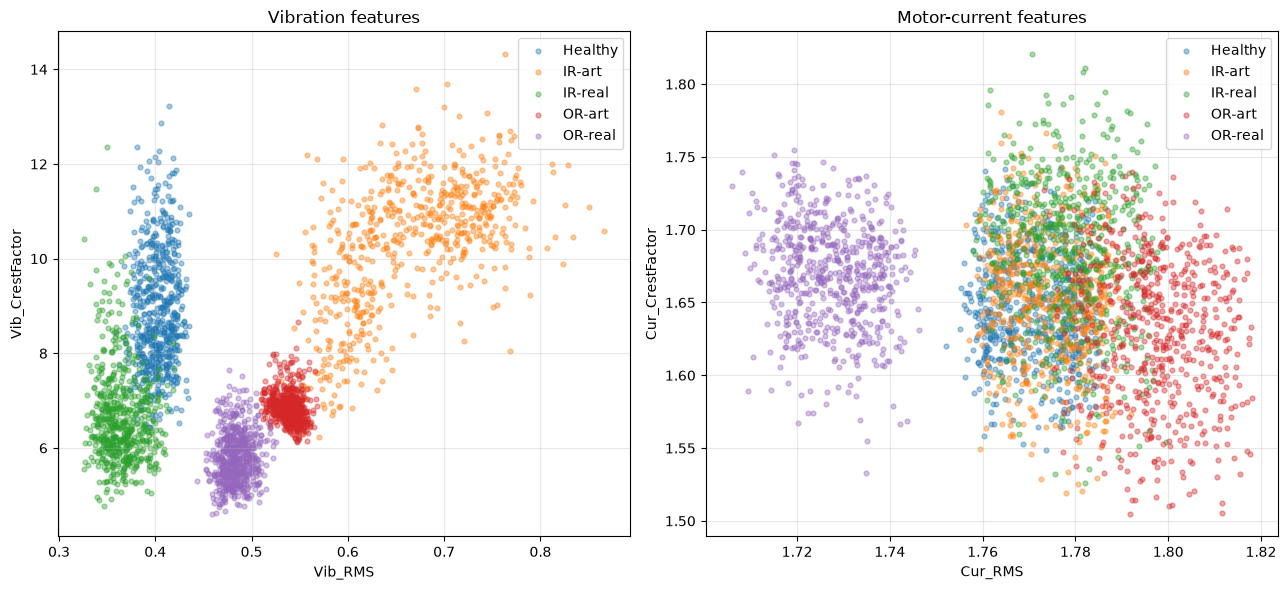

Status                    Healthy      IR-art     IR-real      OR-art  \
Vib_RMS         count  620.000000  620.000000  620.000000  622.000000   
                mean     0.402497    0.664059    0.365029    0.539259   
                std      0.014632    0.066586    0.018902    0.011084   
                min      0.359589    0.525448    0.325599    0.509352   
                25%      0.391843    0.608286    0.350676    0.533325   
                50%      0.402325    0.657248    0.362788    0.540832   
                75%      0.414109    0.718413    0.377394    0.546825   
                max      0.435407    0.866447    0.419496    0.567778   
Vib_CrestFactor count  620.000000  620.000000  620.000000  622.000000   
                mean     8.913734   10.240231    6.663302    6.829895   
                std      1.230300    1.426428    1.004469    0.335481   
                min      6.432864    6.234804    4.765531    6.131991   
                25%      7.972323    9.292677    5.994462    6.590126   
                50%      8.672888   10.498799    6.458055    6.772809   
                75%      9.756768   11.232281    7.096964    7.007343   
                max     13.230362   14.317629   12.353895    8.657944   
Cur_RMS         count  620.000000  620.000000  620.000000  622.000000   
                mean     1.770687    1.774167    1.778641    1.797492   
                std      0.007895    0.008118    0.009333    0.009774   
                min      1.752132    1.756483    1.758010    1.773203   
                25%      1.763649    1.767391    1.771998    1.790850   
                50%      1.770607    1.773716    1.778531    1.797392   
                75%      1.777699    1.781331    1.785273    1.804602   
                max      1.785949    1.792000    1.799423    1.818142   
Cur_CrestFactor count  620.000000  620.000000  620.000000  622.000000   
                mean     1.646716    1.651879    1.686160    1.630209   
                std      0.037306    0.045212    0.048979    0.049718   
                min      1.548774    1.518960    1.525845    1.505059   
                25%      1.620592    1.623590    1.657058    1.594972   
                50%      1.644412    1.653087    1.688019    1.633142   
                75%      1.673987    1.680872    1.719217    1.668081   
                max      1.741953    1.781056    1.820470    1.739828   

Status                    OR-real  
Vib_RMS         count  620.000000  
                mean     0.483698  
                std      0.013507  
                min      0.442904  
                25%      0.474002  
                50%      0.482434  
                75%      0.492479  
                max      0.525686  
Vib_CrestFactor count  620.000000  
                mean     5.809702  
                std      0.535693  
                min      4.614426  
                25%      5.435231  
                50%      5.769119  
                75%      6.153884  
                max      7.645740  
Cur_RMS         count  620.000000  
                mean     1.727397  
                std      0.008334  
                min      1.705896  
                25%      1.720324  
                50%      1.727221  
                75%      1.734113  
                max      1.746374  
Cur_CrestFactor count  620.000000  
                mean     1.669173  
                std      0.035936  
                min      1.532863  
                25%      1.645352  
                50%      1.670692  
                75%      1.692939  
                max      1.754744

In [6]:
fig, (ax_v, ax_c) = plt.subplots(1, 2, figsize=(13, 6))
for label, group in dataset.groupby("Status"):
    ax_v.scatter(group["Vib_RMS"], group["Vib_CrestFactor"], label=label, alpha=0.4, s=12)
    ax_c.scatter(group["Cur_RMS"], group["Cur_CrestFactor"], label=label, alpha=0.4, s=12)
ax_v.set_xlabel("Vib_RMS")
ax_v.set_ylabel("Vib_CrestFactor")
ax_v.set_title("Vibration features")
ax_c.set_xlabel("Cur_RMS")
ax_c.set_ylabel("Cur_CrestFactor")
ax_c.set_title("Motor-current features")
for ax in (ax_v, ax_c):
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

dataset.groupby("Status")[["Vib_RMS", "Vib_CrestFactor", "Cur_RMS", "Cur_CrestFactor"]].describe().T

## Findings (executed 2026-07-28)

1. **CWRU's easy win does not repeat here.** On CWRU, RMS alone separated all
   classes. On PU, **IR-real (KI04) overlaps healthy** in vibration RMS
   (mean 0.365 vs 0.402 — the *fault* is lower!) and sits below it in crest
   factor too. Real bearing damage is not trivially detectable with crude
   time-domain features; frequency-domain / envelope analysis is required.
   This is a known PU-dataset result and exactly why it's a better benchmark.
2. **Artificial ≠ real damage.** OR-art vs OR-real and IR-art vs IR-real form
   *disjoint* clusters (e.g. IR-art RMS ≈ 0.66 vs IR-real ≈ 0.37). A model
   trained on artificial damage would learn the wrong decision boundary for
   real damage — our own measured analogue of Paper 4's 0.12 % cross-domain
   collapse, and direct motivation for RQ4 (sim-to-real domain adaptation).
3. **Motor current carries a weak but present signal.** Cur_RMS shifts are tiny
   (healthy 1.771 → OR-art 1.797, OR-real 1.727; ~1–2 %) yet consistent, with
   non-overlapping quartiles for the OR classes; IR classes are nearly
   indistinguishable. Crude time-domain stats won't be enough for
   current-based diagnosis — MCSA-style spectral features are the next tool.